Enter study hours: 7

Prediction: Pass
Pass Probability: 91.27 %
Fail Probability: 8.73 %


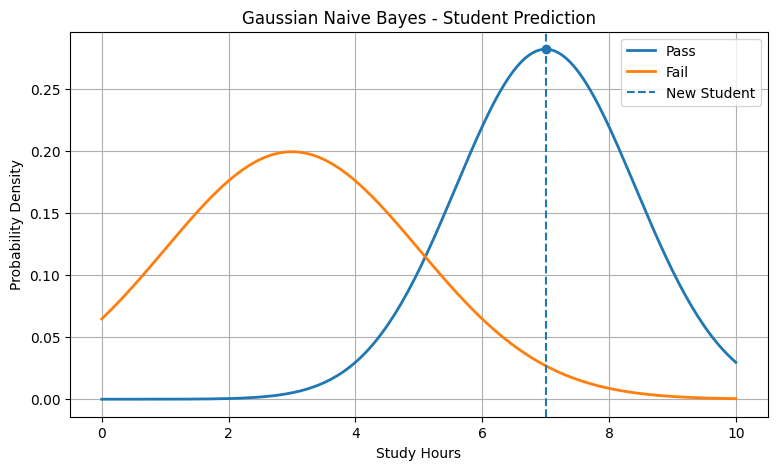

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB

# Training data
pass_students = [5, 6, 7, 8, 9]
fail_students = [0, 2, 3, 4, 6]

X = np.array(pass_students + fail_students).reshape(-1, 1)
y = np.array(['Pass'] * 5 + ['Fail'] * 5)

# Train the model
model = GaussianNB()
model.fit(X, y)

# New student
hours = float(input("Enter study hours: "))

# Predict
prediction = model.predict([[hours]])
probability = model.predict_proba([[hours]])[0]

print("\nPrediction:", prediction[0])
print("Pass Probability:", round(probability[1] * 100, 2), "%")
print("Fail Probability:", round(probability[0] * 100, 2), "%")

# Calculate Gaussian curves
x = np.linspace(0, 10, 200)

pass_mean = np.mean(pass_students)
fail_mean = np.mean(fail_students)

pass_var = np.var(pass_students)
fail_var = np.var(fail_students)

def gaussian(x, mean, var):
    return (1 / np.sqrt(2 * np.pi * var)) * np.exp(
        -((x - mean) ** 2) / (2 * var)
    )

pass_curve = gaussian(x, pass_mean, pass_var)
fail_curve = gaussian(x, fail_mean, fail_var)

# Draw the graph
plt.figure(figsize=(9, 5))

plt.plot(x, pass_curve, label="Pass", linewidth=2)
plt.plot(x, fail_curve, label="Fail", linewidth=2)

plt.axvline(hours, linestyle="--", label="New Student")

plt.scatter([hours],
            [gaussian(hours, pass_mean, pass_var)],
            zorder=3)

plt.title("Gaussian Naive Bayes - Student Prediction")
plt.xlabel("Study Hours")
plt.ylabel("Probability Density")

plt.legend()
plt.grid()
plt.show()
